# Simulation

`yabte.utilities.simulation` generates synthetic price paths with known properties.
Use them to test strategies, for instance to confirm that a strategy finds no edge in a
random walk.

Generators are vectorised over simulations and return arrays indexed
`[time step, simulation, ...]`. Pass a seeded `numpy` generator as `rng` for
reproducible paths.

In [1]:
from decimal import Decimal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from yabte.backtest import Book, OHLCAsset, StrategyRunner
from yabte.utilities.simulation.geometric_brownian_motion import gbm_simulate_paths
from yabte.utilities.simulation.heston import heston_simulate_paths
from yabte.utilities.simulation.weiner import weiner_simulate_paths

from example_strategies import SMAXO

rng = np.random.default_rng(42)


def moments(x):
    """Mean, standard deviation, skew and excess kurtosis."""
    z = (x - x.mean()) / x.std()
    return pd.Series(
        {
            "mean": x.mean(),
            "std": x.std(),
            "skew": (z**3).mean(),
            "excess kurtosis": (z**4).mean() - 3,
        }
    )

## Wiener process

`weiner_simulate_paths(n_steps, n_sims, stdev, R)` returns `W` with shape
`(n_steps, n_sims, k)`, starting at zero. `stdev` is the standard deviation of each
increment. `R` is a `k x k` correlation matrix across the components. With increments
of $\sqrt{\Delta t}$, $\mathrm{Var}(W_t) = t$:

shape: (253, 5000, 1)


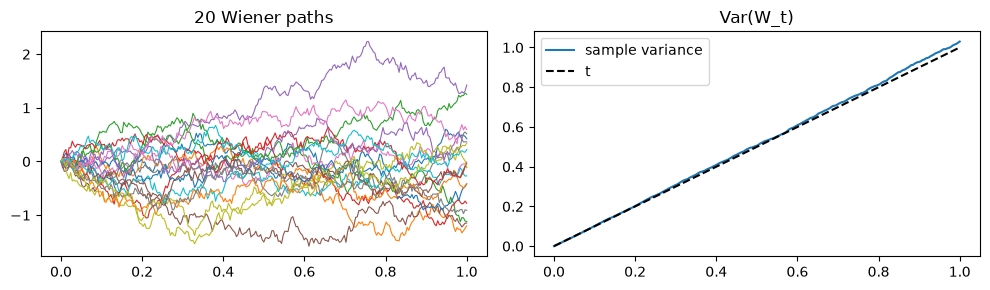

In [2]:
T, n_steps, n_sims = 1.0, 253, 5000
dt = T / (n_steps - 1)
t = np.linspace(0, T, n_steps)

W = weiner_simulate_paths(n_steps=n_steps, n_sims=n_sims, stdev=np.sqrt(dt), rng=rng)
print("shape:", W.shape)

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(t, W[:, :20, 0], lw=0.8)
axs[0].set_title("20 Wiener paths")
axs[1].plot(t, W[:, :, 0].var(axis=1), label="sample variance")
axs[1].plot(t, t, "k--", label="t")
axs[1].set_title("Var(W_t)")
axs[1].legend()
fig.tight_layout()

Pass a correlation matrix to correlate the components' increments:

In [3]:
R = np.array([[1.0, 0.8], [0.8, 1.0]])
W2 = weiner_simulate_paths(
    n_steps=n_steps, n_sims=n_sims, stdev=np.sqrt(dt), R=R, rng=rng
)
dW = np.diff(W2, axis=0).reshape(-1, 2)
print(f"sample correlation of increments: {np.corrcoef(dW.T)[0, 1]:.3f}")

sample correlation of increments: 0.800


## Geometric Brownian motion

$dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$. Paths use the exact solution
$S_t = S_0 \exp\left((\mu - \sigma^2/2)t + \sigma W_t\right)$, so there's no
discretisation error. `mu` and `sigma` take one entry per asset, and `R` correlates the
assets. $S_T$ is lognormal with mean $S_0 e^{\mu T}$:

E[S_T]: sample 105.38, theory 105.13


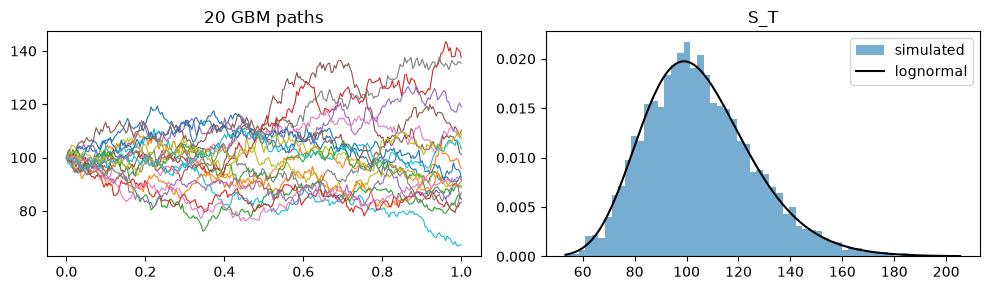

In [4]:
S0, mu, sigma = 100.0, 0.05, 0.2
S = gbm_simulate_paths(
    S0=S0, mu=mu, sigma=sigma, R=1, T=T, n_steps=n_steps, n_sims=n_sims, rng=rng
)[:, :, 0]

S_T = S[-1]
print(f"E[S_T]: sample {S_T.mean():.2f}, theory {S0 * np.exp(mu * T):.2f}")

# lognormal density of S_T
x = np.linspace(S_T.min(), S_T.max(), 200)
m, s = np.log(S0) + (mu - sigma**2 / 2) * T, sigma * np.sqrt(T)
pdf = np.exp(-((np.log(x) - m) ** 2) / (2 * s**2)) / (x * s * np.sqrt(2 * np.pi))

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(t, S[:, :20], lw=0.8)
axs[0].set_title("20 GBM paths")
axs[1].hist(S_T, bins=60, density=True, alpha=0.6, label="simulated")
axs[1].plot(x, pdf, "k", label="lognormal")
axs[1].set_title("S_T")
axs[1].legend()
fig.tight_layout()

Three correlated assets with different drifts and volatilities:

In [5]:
R3 = np.array([[1.0, 0.6, 0.2], [0.6, 1.0, 0.4], [0.2, 0.4, 1.0]])
P = gbm_simulate_paths(
    S0=np.array([100.0, 50.0, 20.0]),
    mu=np.array([0.05, 0.08, 0.02]),
    sigma=np.array([0.15, 0.3, 0.25]),
    R=R3,
    T=T,
    n_steps=n_steps,
    n_sims=n_sims,
    rng=rng,
)
log_returns = np.diff(np.log(P), axis=0).reshape(-1, 3)
print("shape:", P.shape)
pd.DataFrame(
    np.corrcoef(log_returns.T), index=["A", "B", "C"], columns=["A", "B", "C"]
).round(2)

shape: (253, 5000, 3)


,A,B,C
A,1.0,0.6,0.2
B,0.6,1.0,0.4
C,0.2,0.4,1.0


## Heston stochastic volatility

Variance $\nu_t$ follows its own mean-reverting process:

$$dS_t = \mu S_t\,dt + \sqrt{\nu_t} S_t\,dW^S_t, \qquad
d\nu_t = \kappa(\theta - \nu_t)\,dt + \xi\sqrt{\nu_t}\,dW^\nu_t$$

$\kappa$ sets the speed of mean reversion and $\theta$ the long-run variance. $\xi$ is
the volatility of variance, and `R` correlates the two Wiener processes. The function
returns `(S, v)`, each shaped `(n_steps, n_sims)`. `v` is variance, not volatility.
Expected variance decays from $\nu_0$ towards $\theta$ as
$E[\nu_t] = \theta + (\nu_0 - \theta)e^{-\kappa t}$.

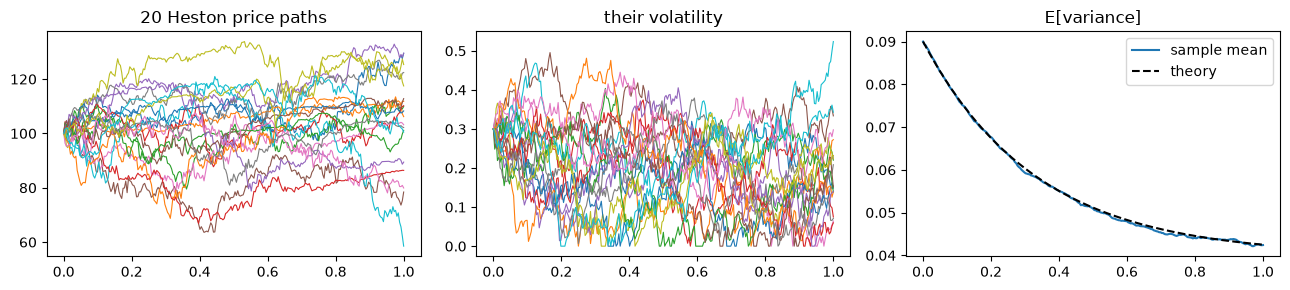

In [6]:
kappa, theta, v0, xi, rho = 3.0, 0.04, 0.09, 0.6, -0.7
S_h, v_h = heston_simulate_paths(
    S0=S0,
    v0=v0,
    mu=mu,
    kappa=kappa,
    theta=theta,
    xi=xi,
    R=np.array([[1.0, rho], [rho, 1.0]]),
    T=T,
    n_steps=n_steps,
    n_sims=n_sims,
    rng=rng,
)

fig, axs = plt.subplots(1, 3, figsize=(13, 3))
axs[0].plot(t, S_h[:, :20], lw=0.8)
axs[0].set_title("20 Heston price paths")
axs[1].plot(t, np.sqrt(v_h[:, :20]), lw=0.8)
axs[1].set_title("their volatility")
axs[2].plot(t, v_h.mean(axis=1), label="sample mean")
axs[2].plot(t, theta + (v0 - theta) * np.exp(-kappa * t), "k--", label="theory")
axs[2].set_title("E[variance]")
axs[2].legend()
fig.tight_layout()

Negative correlation between price and variance means volatility rises as prices
fall. Heston returns then skew left, with fatter tails than GBM's normal log returns.
One-year log returns against GBM at a similar average volatility:

,GBM,Heston
mean,0.024,0.022
std,0.235,0.250
skew,-0.001,-1.349
excess kurtosis,-0.043,3.169


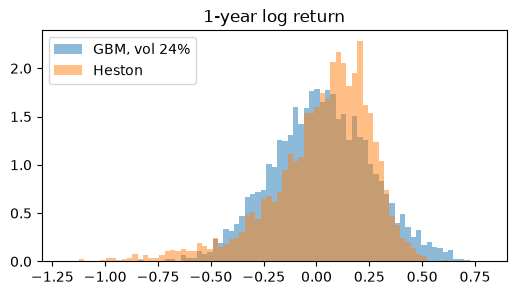

In [7]:
avg_vol = np.sqrt(v_h.mean())
S_g = gbm_simulate_paths(
    S0=S0, mu=mu, sigma=avg_vol, R=1, T=T, n_steps=n_steps, n_sims=n_sims, rng=rng
)[:, :, 0]

r_heston = np.log(S_h[-1] / S0)
r_gbm = np.log(S_g[-1] / S0)

fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(-1.2, 0.8, 80)
ax.hist(r_gbm, bins=bins, alpha=0.5, density=True, label=f"GBM, vol {avg_vol:.0%}")
ax.hist(r_heston, bins=bins, alpha=0.5, density=True, label="Heston")
ax.set_title("1-year log return")
ax.legend()

pd.DataFrame({"GBM": moments(r_gbm), "Heston": moments(r_heston)}).round(3)

## Backtesting on simulated data

Zero-drift GBM is a random walk, and no strategy should beat it on average. The
crossover strategy from [Engines & Parameter Sweeps](Engines_and_Parameter_Sweeps.ipynb)
runs on 40 simulated years, one path per one-asset dataset. `Close` is enough, because
`OHLCAsset` fills at the close when `High` and `Low` are missing.

mean P&L -106 +/- 498 (95% interval)


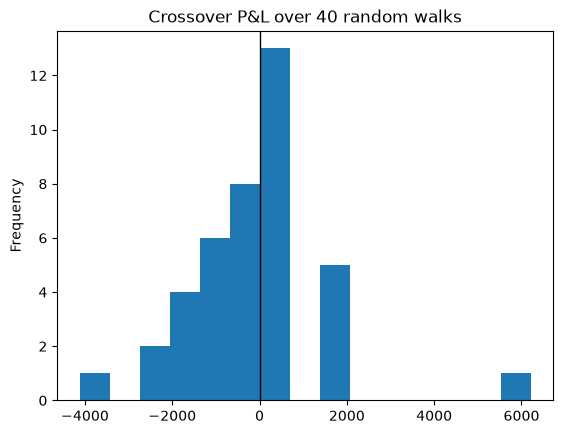

In [8]:
n_paths = 40
days = pd.bdate_range("2024-01-01", periods=252)
paths = gbm_simulate_paths(
    S0=100.0, mu=0.0, sigma=0.25, R=1, T=1, n_steps=len(days), n_sims=n_paths, rng=rng
)[:, :, 0]

pnl = []
for i in range(n_paths):
    data = pd.DataFrame({("SIM", "Close"): paths[:, i]}, index=days)
    srr = StrategyRunner(
        data=data,
        assets=[OHLCAsset(name="SIM")],
        strategies=[SMAXO()],
        books=[Book(name="Main", cash=Decimal("100000"))],
    ).run({"days_short": 10, "days_long": 30})
    total = srr.book_history[("Main", "total")]
    pnl.append(total.iloc[-1] - total.iloc[0])

pnl = pd.Series(pnl)
se = pnl.std() / np.sqrt(len(pnl))
print(f"mean P&L {pnl.mean():,.0f} +/- {1.96 * se:,.0f} (95% interval)")
ax = pnl.plot.hist(bins=15, title=f"Crossover P&L over {n_paths} random walks")
ax.axvline(0, color="k", lw=1);

The interval should contain zero. Consistent profits here would point to a bug,
usually look-ahead into data the strategy couldn't have known.